**ARX with news sentiment**

The AR(1) equation was:

$$Inflation_t = c + \phi Inflation_{t-1} + error_t$$

ARX means **autoregressive model with an external input X**. Here, X is news sentiment:

$$Inflation_t = c + \phi Inflation_{t-1} + \beta Sentiment_{t-1} + error_t$$

- $\phi$ measures the relationship with last month's inflation.
- $\beta$ measures whether last month's sentiment adds information after accounting for past inflation.

In [1]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

# Keep the same split used in Part 2.
TEST_START = '2017-01-01'

# Database settings are loaded from the project-root .env file.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
sys.path.insert(0, str(PROJECT_ROOT))
from modelling.config import get_sqlalchemy_engine
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'

print('Selected source:', DATA_SOURCE)

Selected source: database


**Load CPI and monthly sentiment**

In [3]:
if DATA_SOURCE == 'database':
    from sqlalchemy import create_engine, text

    engine = get_sqlalchemy_engine()
    query = text("""
        SELECT month_date, cpi_value, avg_monthly_sentiment
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={
        'month_date': 'Date',
        'cpi_value': 'CPI',
        'avg_monthly_sentiment': 'News_Sentiment',
    })
else:
    raw = pd.read_csv(
        CSV_PATH,
        usecols=['Date', 'CPIAUCSL', 'News_Sentiment'],
        parse_dates=['Date'],
    ).rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw[['CPI', 'News_Sentiment']] = raw[['CPI', 'News_Sentiment']].apply(
    pd.to_numeric, errors='coerce'
)
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())
raw.head()

Rows: 204
Period: 2007-01-01 to 2023-12-01


,CPI,News_Sentiment
Date,,
2007-01-01,203.437,-0.329116
2007-02-01,204.226,-0.170357
2007-03-01,205.288,-0.404710
2007-04-01,205.904,-0.275370
2007-05-01,206.755,-0.172399


**Create only information known before the forecast month**

In [4]:
data = raw.copy()
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100
data['Inflation_Lag1'] = data['Inflation_MoM'].shift(1)
data['Sentiment_Lag1'] = data['News_Sentiment'].shift(1)

model_data = data[[
    'Inflation_MoM', 'Inflation_Lag1', 'Sentiment_Lag1'
]].dropna().copy()

model_data.head(6)

,Inflation_MoM,Inflation_Lag1,Sentiment_Lag1
Date,,,
2007-03-01,0.520012,0.387835,-0.170357
2007-04-01,0.300066,0.520012,-0.404710
2007-05-01,0.413299,0.300066,-0.275370
2007-06-01,0.231675,0.413299,-0.172399
2007-07-01,0.178060,0.231675,-0.309985
2007-08-01,0.030828,0.178060,-0.296646


**Use the same training and test periods**

In [5]:
test_start = pd.Timestamp(TEST_START)
train = model_data.loc[model_data.index < test_start].copy()
test = model_data.loc[model_data.index >= test_start].copy()

if train.empty or test.empty:
    raise ValueError('The selected TEST_START must leave observations in both periods.')

print('Training period:', train.index.min().date(), 'to', train.index.max().date())
print('Training months:', len(train))
print('Test period:    ', test.index.min().date(), 'to', test.index.max().date())
print('Test months:    ', len(test))

Training period: 2007-03-01 to 2016-12-01
Training months: 118
Test period:     2017-01-01 to 2023-12-01
Test months:     84


**Estimate AR(1) and ARX using OLS**

In [6]:
# AR(1): previous inflation only
X_train_ar1 = sm.add_constant(train[['Inflation_Lag1']], has_constant='add')
ar1_model = sm.OLS(train['Inflation_MoM'], X_train_ar1).fit()

# ARX: previous inflation plus previous sentiment
X_train_arx = sm.add_constant(
    train[['Inflation_Lag1', 'Sentiment_Lag1']], has_constant='add'
)
arx_model = sm.OLS(train['Inflation_MoM'], X_train_arx).fit()

coefficients = pd.DataFrame({
    'AR(1)': [ar1_model.params['const'], ar1_model.params['Inflation_Lag1'], np.nan],
    'ARX': [
        arx_model.params['const'],
        arx_model.params['Inflation_Lag1'],
        arx_model.params['Sentiment_Lag1'],
    ],
}, index=['Constant', 'Previous inflation', 'Previous sentiment'])
coefficients

,AR(1),ARX
Constant,0.069392,0.123561
Previous inflation,0.522808,0.521292
Previous sentiment,NaN,0.179585


In [7]:
beta = arx_model.params['Sentiment_Lag1']
print(f'ARX sentiment coefficient (beta): {beta:.4f}')
print(f'Effect in the equation of a +0.10 sentiment change: {0.10 * beta:.4f}')

ARX sentiment coefficient (beta): 0.1796
Effect in the equation of a +0.10 sentiment change: 0.0180


**Forecast the same test months**

In [8]:
X_test_ar1 = sm.add_constant(test[['Inflation_Lag1']], has_constant='add')
X_test_arx = sm.add_constant(
    test[['Inflation_Lag1', 'Sentiment_Lag1']], has_constant='add'
)

test['Forecast_AR1'] = ar1_model.predict(X_test_ar1)
test['Forecast_ARX'] = arx_model.predict(X_test_arx)

test[[
    'Inflation_MoM', 'Inflation_Lag1', 'Sentiment_Lag1',
    'Forecast_AR1', 'Forecast_ARX'
]].head(10)

,Inflation_MoM,Inflation_Lag1,Sentiment_Lag1,Forecast_AR1,Forecast_ARX
Date,,,,,
2017-01-01,0.404308,0.252452,-0.105475,0.201376,0.236220
2017-02-01,0.159266,0.404308,-0.132172,0.280768,0.310587
2017-03-01,-0.046720,0.159266,-0.137779,0.152658,0.181842
2017-04-01,0.123415,-0.046720,0.046487,0.044967,0.107554
2017-05-01,-0.077398,0.123415,-0.385277,0.133915,0.118706
2017-06-01,0.065163,-0.077398,-0.152224,0.028928,0.055877
2017-07-01,0.032765,0.065163,-0.295361,0.103460,0.104487
2017-08-01,0.384863,0.032765,-0.298291,0.086522,0.087072
2017-09-01,0.510639,0.384863,-0.302055,0.270602,0.269942


**Compare RMSE, MAE, and mean error**


In [9]:
ar1_errors = test['Inflation_MoM'] - test['Forecast_AR1']
arx_errors = test['Inflation_MoM'] - test['Forecast_ARX']

ar1_rmse = np.sqrt(np.mean(ar1_errors ** 2))
arx_rmse = np.sqrt(np.mean(arx_errors ** 2))
ar1_mae = np.mean(np.abs(ar1_errors))
arx_mae = np.mean(np.abs(arx_errors))
ar1_mean_error = np.mean(ar1_errors)
arx_mean_error = np.mean(arx_errors)

metric_comparison = pd.DataFrame({
    'RMSE': [ar1_rmse, arx_rmse],
    'MAE': [ar1_mae, arx_mae],
    'Mean Error (Actual - Forecast)': [ar1_mean_error, arx_mean_error],
}, index=['AR(1)', 'ARX with lagged sentiment'])
metric_comparison

,RMSE,MAE,Mean Error (Actual - Forecast)
AR(1),0.265153,0.195604,0.067525
ARX with lagged sentiment,0.266704,0.196726,0.065917


In [12]:
rmse_change = ar1_rmse - arx_rmse
mae_change = ar1_mae - arx_mae

print(f'ARX change in RMSE: {rmse_change:.4f}')
print(f'ARX change in MAE: {mae_change:.4f}')

ARX change in RMSE: -0.0016
ARX change in MAE: -0.0011


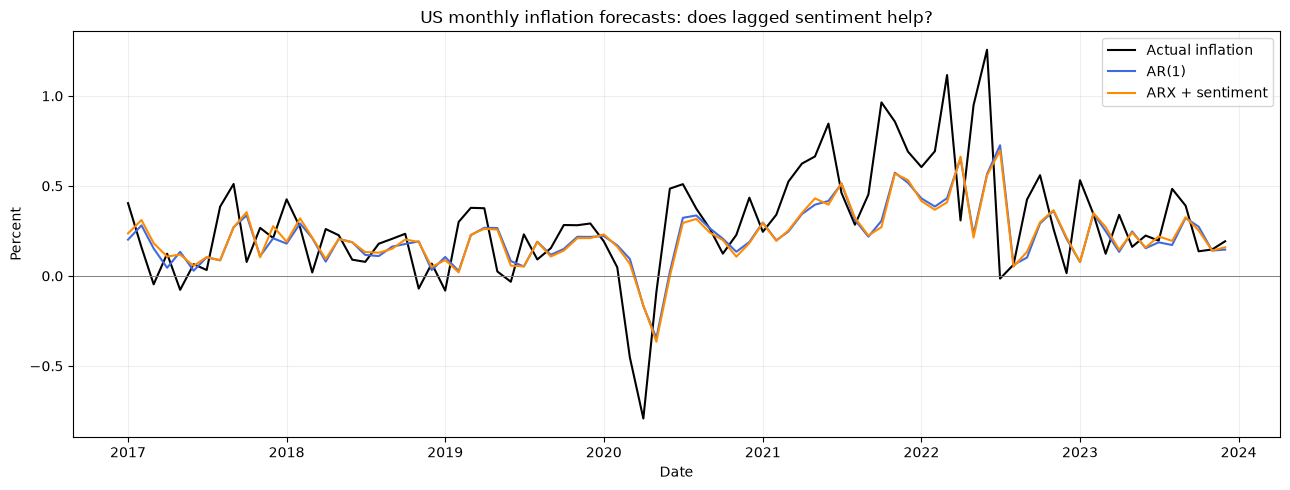

In [11]:
plt.figure(figsize=(13, 5))
plt.plot(test.index, test['Inflation_MoM'], label='Actual inflation', color='black')
plt.plot(test.index, test['Forecast_AR1'], label='AR(1)', color='royalblue')
plt.plot(test.index, test['Forecast_ARX'], label='ARX + sentiment', color='darkorange')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('US monthly inflation forecasts: does lagged sentiment help?')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()